# *Flaviviridae* glycoprotein fold trees

Proof of concept that ESM3Di 3Di groups the most similar glycoprotein structures together.
Trees are built with `esm3di foldtree` from the amino-acid sequences of the E, E1 and E2
glycoprotein structures of Mifsud et al., *Mapping glycoprotein structure reveals Flaviviridae
evolutionary history* (structures: [Zenodo 11092288](https://zenodo.org/records/11092288)):

1. **ESM3Di FoldTree**: ESM3Di predicts 3Di from the sequences.
2. **AlphaFold2 FoldTree** (structure reference): `foldseek createdb` computes 3Di from the
   predicted structures; the rest of the `esm3di foldtree` workflow is run unchanged. All E1 and E2
   structures come from AlphaFold2; 51 of the 247 E structures come from ESMFold.

Each method gives four trees: each protein alone, and E, E1 and E2 together. The combined trees are
only scored here, and their searches are the input of `flaviviridae_group_auc.ipynb`.

Tips are labelled with a six-letter code, protein (`E0` for E, `E1`, `E2`) followed by the
four-letter group code of Mifsud et al., e.g. `E1HPHV_...`. The monophyly score is the share of
internal nodes whose descendant tips all share that code. It is a label-purity summary, not a
measure of phylogenetic accuracy. Sequences with an unclassified code (..UN) are left out before the
trees of the figures and their scores are built.

Steps: 1. build the trees, 2. add the six-letter labels, 3. monophyly and ultrametricity, 4. agreement of the predicted 3Di
with the structures, 5. figures.

**Figures** (written to `figures/`): the E2 trees (panel b of Figure 2), and all E, E1 and E2 trees (a supplementary
figure). `paper/` assembles them. Tables: `results/flaviviridae_monophyly.csv`, `results/flaviviridae_3di_agreement.csv`.
Jackknife of the scores: `flaviviridae_jackknife.ipynb`.

In [1]:
import shutil
import subprocess
import tempfile
from importlib.resources import as_file, files
from pathlib import Path

import numpy as np
import pandas as pd
from Bio import Phylo

from foldtree_resample import build_tree, load_allvall
from monophyly import glycoprotein_labels, relabel_tree, score_monophyly, ultrametricity
from tree_plot import FIGURE2_PANEL_HEIGHT_MM, FIGURE2_SCORE_TABLE_TOP_MM, SUBTITLE_MM, group_colors, group_legend, parse_tip, tip_keys, tree_grid

INPUT_DIR = Path("flaviviridae_inputs")
PDB_DIR = Path("/scratch/fweikert/glyco_pdbs")                  # AlphaFold2 structures (not tracked)
OUTPUT_DIR = Path("/scratch/fweikert/phylogeny/flaviviridae")    # esm3di foldtree runs (not tracked)
FIGURE_DIR = Path("figures")
CORES = 8

DATASETS = {
    "fullglyco": "refolded_fullglyco_aa.fas",        # E, E1 and E2 together
    "fullglyco_E": "refolded_fullglyco_E_aa.fas",
    "fullglyco_E1": "refolded_fullglyco_E1_aa.fas",
    "fullglyco_E2": "refolded_fullglyco_E2_aa.fas",
}
# PDB folders of each dataset; file names match the FASTA headers
STRUCTURES = {
    "fullglyco": [PDB_DIR / f"refolded_fullglyco_{p}" for p in ("E", "E1", "E2")],
    "fullglyco_E": [PDB_DIR / "refolded_fullglyco_E"],
    "fullglyco_E1": [PDB_DIR / "refolded_fullglyco_E1"],
    "fullglyco_E2": [PDB_DIR / "refolded_fullglyco_E2"],
}
MODELS = ("esm3di",)              # 3Di predicted from sequence
TREES = MODELS + ("af2",)         # plus 3Di from the structures


def raw_tree(model, dataset):
    """Rooted tree written by esm3di foldtree."""
    return OUTPUT_DIR / f"{model}_{dataset}" / f"{model}_struct_tree.PP.nwk.rooted"


def labelled_tree(model, dataset):
    return OUTPUT_DIR / "labelled" / f"{model}_{dataset}.nwk"

## 1. Build the trees

### 1a. From sequence

Runs `esm3di foldtree` once per dataset; existing runs are skipped. Run on a GPU node
with ESM3Di installed; Snakemake creates the workflow's conda environment in
`OUTPUT_DIR/.snakemake_conda` on first use.

In [2]:
for dataset, fasta in DATASETS.items():
    for model in MODELS:
        if raw_tree(model, dataset).exists():
            print(f"Exists, skipping: {raw_tree(model, dataset)}")
            continue
        cmd = ["esm3di", "foldtree", "-i", str(INPUT_DIR / fasta), "-o", str(OUTPUT_DIR),
               "-d", f"{model}_{dataset}", "-c", str(CORES)]
        print(" ".join(cmd))
        subprocess.run(cmd, check=True)

Exists, skipping: /scratch/fweikert/phylogeny/flaviviridae/esm3di_fullglyco/esm3di_struct_tree.PP.nwk.rooted
Exists, skipping: /scratch/fweikert/phylogeny/flaviviridae/esm3di_fullglyco_E/esm3di_struct_tree.PP.nwk.rooted
Exists, skipping: /scratch/fweikert/phylogeny/flaviviridae/esm3di_fullglyco_E1/esm3di_struct_tree.PP.nwk.rooted
Exists, skipping: /scratch/fweikert/phylogeny/flaviviridae/esm3di_fullglyco_E2/esm3di_struct_tree.PP.nwk.rooted


### 1b. From the AlphaFold2 structures

`foldseek createdb` turns the PDB files into a Foldseek database (3Di from the structures). The
`esm3di foldtree` Snakefile then runs from that database exactly as for the sequence trees: the
workflow is staged and called as `esm3di foldtree` does, with the same conda environment, but only
the rules after the database step are allowed (`--allowed-rules`), so Snakemake takes the database
as given instead of predicting 3Di with ESM3Di. `foldseek` is the one in the workflow's `foldtree`
conda environment (created by step 1a), so database and search use the same Foldseek version.

In [3]:
WORKFLOW_DIR = OUTPUT_DIR / ".workflow_structures"   # staged copy of the workflow, as esm3di foldtree does
CONDA_PREFIX = OUTPUT_DIR / ".snakemake_conda"       # shared with the esm3di foldtree runs
TREE_RULES = ["foldseek_allvall", "foldseek2distmat", "quicktree", "postprocess_tree", "mad_root_struct"]


def run_workflow(dataset):
    """Run the esm3di foldtree Snakefile for af2_{dataset}, from the database onwards."""
    cmd = [
        "snakemake", str(raw_tree("af2", dataset).resolve()),
        "--snakefile", "Snakefile", "--cores", str(CORES), "--scheduler", "greedy",
        # input_path is required by the Snakefile but unused: the database rule is not allowed
        "--config", f"input_path={(INPUT_DIR / DATASETS[dataset]).resolve()}",
        f"output_dir={OUTPUT_DIR.resolve()}", f"dataset=af2_{dataset}", "use_prostt5=False",
        "--use-conda", "--conda-frontend", "conda", "--conda-prefix", str(CONDA_PREFIX.resolve()),
        "--allowed-rules", *TREE_RULES,
    ]
    print(" ".join(cmd))
    subprocess.run(cmd, cwd=WORKFLOW_DIR, check=True)


def foldtree_env():
    """The conda environment Snakemake built from envs/foldtree.yaml."""
    spec = (WORKFLOW_DIR / "envs" / "foldtree.yaml").read_text()
    for yaml in CONDA_PREFIX.glob("*.yaml"):
        env = yaml.with_suffix("")
        if yaml.read_text() == spec and env.is_dir():
            return env
    raise FileNotFoundError(f"No foldtree environment in {CONDA_PREFIX}; run step 1a first.")


shutil.rmtree(WORKFLOW_DIR, ignore_errors=True)
with as_file(files("esm3di").joinpath("workflow")) as source:
    shutil.copytree(source, WORKFLOW_DIR, ignore=shutil.ignore_patterns(".snakemake", "__pycache__"))

for dataset, pdb_dirs in STRUCTURES.items():
    if raw_tree("af2", dataset).exists():
        print(f"Exists, skipping: {raw_tree('af2', dataset)}")
        continue
    run_dir = OUTPUT_DIR / f"af2_{dataset}"
    (run_dir / "logs").mkdir(parents=True, exist_ok=True)
    # createdb takes one directory or a list of files
    pdbs = sorted(str(pdb) for pdb_dir in pdb_dirs for pdb in pdb_dir.glob("*.pdb"))
    cmd = [str(foldtree_env() / "bin" / "foldseek"), "createdb", *pdbs,
           str(run_dir / "db"), "--threads", str(CORES)]
    print(f"foldseek createdb: {len(pdbs)} structures -> {run_dir / 'db'}")
    with open(run_dir / "logs" / "foldseek_createdb.log", "w") as log:
        subprocess.run(cmd, stdout=log, stderr=subprocess.STDOUT, check=True)
    run_workflow(dataset)
shutil.rmtree(WORKFLOW_DIR)

Exists, skipping: /scratch/fweikert/phylogeny/flaviviridae/af2_fullglyco/af2_struct_tree.PP.nwk.rooted
Exists, skipping: /scratch/fweikert/phylogeny/flaviviridae/af2_fullglyco_E/af2_struct_tree.PP.nwk.rooted
Exists, skipping: /scratch/fweikert/phylogeny/flaviviridae/af2_fullglyco_E1/af2_struct_tree.PP.nwk.rooted
Exists, skipping: /scratch/fweikert/phylogeny/flaviviridae/af2_fullglyco_E2/af2_struct_tree.PP.nwk.rooted


## 2. Six-letter labels

`esm3di foldtree` names the tips after the FASTA headers, or the PDB file names for the structure
trees; both are `HPHV_..._AlphaFold`. The protein code
is taken from the E, E1 or E2 FASTA that holds the sequence, giving the labels of the archived trees.

In [4]:
labels = glycoprotein_labels({
    "E": INPUT_DIR / "refolded_fullglyco_E_aa.fas",
    "E1": INPUT_DIR / "refolded_fullglyco_E1_aa.fas",
    "E2": INPUT_DIR / "refolded_fullglyco_E2_aa.fas",
})
for dataset in DATASETS:
    for model in TREES:
        relabel_tree(raw_tree(model, dataset), labelled_tree(model, dataset), labels)
print(f"{len(labels)} labels, e.g. {next(iter(labels.values()))}")

626 labels, e.g. E0FJAF_Cnidaria_flavivirus_E_278-749_AlphaFold


## 3. Monophyly and ultrametricity

`fraction_without_unclassified`: the same score for the tree built without the sequences with an unclassified code
(..UN). Each such sequence is a group of its own, so it lowers the score by every node above it that would otherwise
hold one group. The trees are rebuilt from the all-vs-all results of step 1 with the steps of `esm3di foldtree`
(`foldtree_resample.build_tree`): a pair's identity does not depend on the other sequences in the search, so this equals
leaving these sequences out from the start. `flaviviridae_jackknife.ipynb` checks that the rebuild reproduces the workflow trees.

`root_to_tip_cv` measures ultrametricity: the coefficient of variation (standard deviation / mean) of the
root-to-tip distances in the MAD-rooted tree (`monophyly.ultrametricity`). 0 means all tips are equally far from
the root; being relative, it compares trees with different distance scales.


In [5]:
DATASET_NAMES = {"fullglyco_E": "E", "fullglyco_E1": "E1", "fullglyco_E2": "E2", "fullglyco": "E/E1/E2"}
METHOD_NAMES = {"esm3di": "ESM3Di FoldTree", "af2": "AlphaFold2 FoldTree"}
MODE = "six_letter"
QUICKTREE = next(OUTPUT_DIR.glob(".snakemake_conda/*/bin/quicktree"))   # installed by esm3di foldtree


def without_unclassified(model, dataset):
    """The labelled tree built from the all-vs-all search without the sequences with an unclassified code (..UN)."""
    table = load_allvall(OUTPUT_DIR / f"{model}_{dataset}" / "allvall_1.csv")
    unclassified = {name for name in set(table["query"]) if parse_tip(labels[name], MODE)[2] == "UN"}
    table = table[~table["query"].isin(unclassified) & ~table["target"].isin(unclassified)]
    output = labelled_tree(model, dataset).with_name(f"{model}_{dataset}_classified.nwk")
    with tempfile.TemporaryDirectory() as workdir:
        return relabel_tree(build_tree(table, workdir, QUICKTREE), output, labels)


classified_trees = {(model, dataset): without_unclassified(model, dataset) for dataset in DATASET_NAMES for model in TREES}
rows = []
for dataset, protein in DATASET_NAMES.items():
    for model in TREES:
        tree, classified = labelled_tree(model, dataset), classified_trees[model, dataset]
        rows.append((protein, METHOD_NAMES[model], *score_monophyly(tree, verbose=False),
                     score_monophyly(classified, verbose=False)[2], ultrametricity(tree), ultrametricity(classified)))
scores = pd.DataFrame(rows, columns=["protein", "tree", "monophyletic", "internal_nodes", "fraction",
                                     "fraction_without_unclassified", "root_to_tip_cv", "root_to_tip_cv_without_unclassified"])
scores.to_csv("results/flaviviridae_monophyly.csv", index=False)
scores.round(4)


,protein,tree,monophyletic,internal_nodes,fraction,fraction_without_unclassified,root_to_tip_cv,root_to_tip_cv_without_unclassified
0,E,ESM3Di FoldTree,213,246,0.8659,0.8979,0.0141,0.0141
1,E,AlphaFold2 FoldTree,216,246,0.8780,0.9149,0.0332,0.0209
2,E1,ESM3Di FoldTree,180,189,0.9524,0.9574,0.0086,0.0080
3,E1,AlphaFold2 FoldTree,176,189,0.9312,0.9628,0.0140,0.0135
4,E2,ESM3Di FoldTree,180,188,0.9574,0.9786,0.0111,0.0133
5,E2,AlphaFold2 FoldTree,180,188,0.9574,0.9679,0.0249,0.0267
6,E/E1/E2,ESM3Di FoldTree,556,625,0.8896,0.9167,0.0155,0.0179
7,E/E1/E2,AlphaFold2 FoldTree,490,625,0.7840,0.8007,0.0508,0.1469


## 4. Agreement of the predicted 3Di with the structures

Per sequence, the share of residues whose ESM3Di 3Di state equals the 3Di state of the structure (`_ss` databases
of the runs; same residues, so no alignment is needed). Cohen's kappa over all residues corrects the identity for
chance agreement, which matters because the predictions use fewer distinct states. Also the letter entropy of the
3Di: predicted 3Di uses fewer distinct states than 3Di from structures.


In [6]:
def read_3di(model, dataset):
    """3Di string per tip of a run's Foldseek database."""
    run = OUTPUT_DIR / f"{model}_{dataset}"
    names = dict(line.split("\t")[:2] for line in open(run / "db.lookup"))
    data = (run / "db_ss").read_bytes()
    sequences = {}
    for line in open(run / "db_ss.index"):
        key, offset, length = line.split()[:3]
        sequences[names[key].removesuffix(".pdb")] = data[int(offset):int(offset) + int(length)].rstrip(b"\x00\n").decode()
    return sequences


def entropy(sequences):
    counts = np.unique(list("".join(sequences.values())), return_counts=True)[1]
    shares = counts / counts.sum()
    return -(shares * np.log2(shares)).sum()


def cohen_kappa(predicted, reference):
    predicted, reference = (np.array(list("".join(states))) for states in (predicted, reference))
    chance = sum((predicted == state).mean() * (reference == state).mean() for state in np.unique(reference))
    return ((predicted == reference).mean() - chance) / (1 - chance)


rows = []
for dataset, protein in list(DATASET_NAMES.items())[:3]:
    states = {model: read_3di(model, dataset) for model in TREES}
    tips = sorted(states["af2"])
    identity = [np.mean([a == b for a, b in zip(states["esm3di"][tip], states["af2"][tip])]) for tip in tips]
    rows.append({"protein": protein, "sequences": len(tips),
                 "ESM3Di identity to structure 3Di": np.mean(identity),
                 "ESM3Di kappa": cohen_kappa([states["esm3di"][tip] for tip in tips], [states["af2"][tip] for tip in tips]),
                 **{f"{model} entropy (bits)": entropy(states[model]) for model in TREES}})
agreement = pd.DataFrame(rows).set_index("protein")
agreement.to_csv("results/flaviviridae_3di_agreement.csv")
agreement.round(3)

,sequences,ESM3Di identity to structure 3Di,ESM3Di kappa,esm3di entropy (bits),af2 entropy (bits)
protein,,,,,
E,247,0.386,0.288,2.686,3.878
E1,190,0.477,0.321,2.093,3.262
E2,189,0.339,0.221,2.325,3.805


## 5. Figures

Radial trees (`tree_plot.py`), built without the sequences with an unclassified code (section 3); the scores are
`fraction_without_unclassified` and
`root_to_tip_cv_without_unclassified` (ultrametricity) of section 3. Each group code of a protein has its own hue, the same in the trees
of both methods. The trees of a figure are rotated or mirrored onto a reference tree to ease the comparison, which
changes nothing about them. Trees in a row or panel share one scale.

- `figures/flaviviridae_e2_trees`: E2, ESM3Di above AlphaFold2 (panel b of Figure 2). `figures/parts/` has each tree and the legend as
  separate files at the same scale.
- `figures/flaviviridae_glycoprotein_trees`: E, E1 and E2, both methods, one legend per protein.


flaviviridae_e2_trees: score table covering 0.0 mm2 of tree, with its margin
flaviviridae_e2_trees: legend in 1 column(s), covering 0.0 mm2 of tree


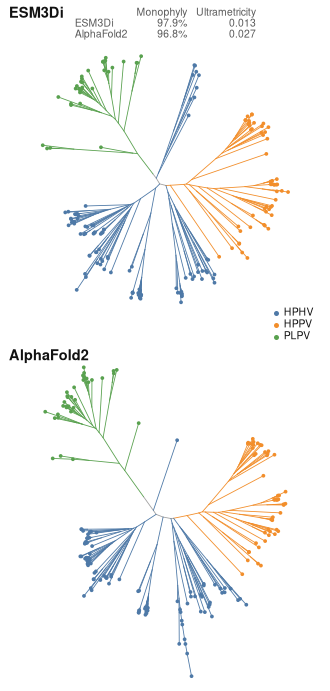

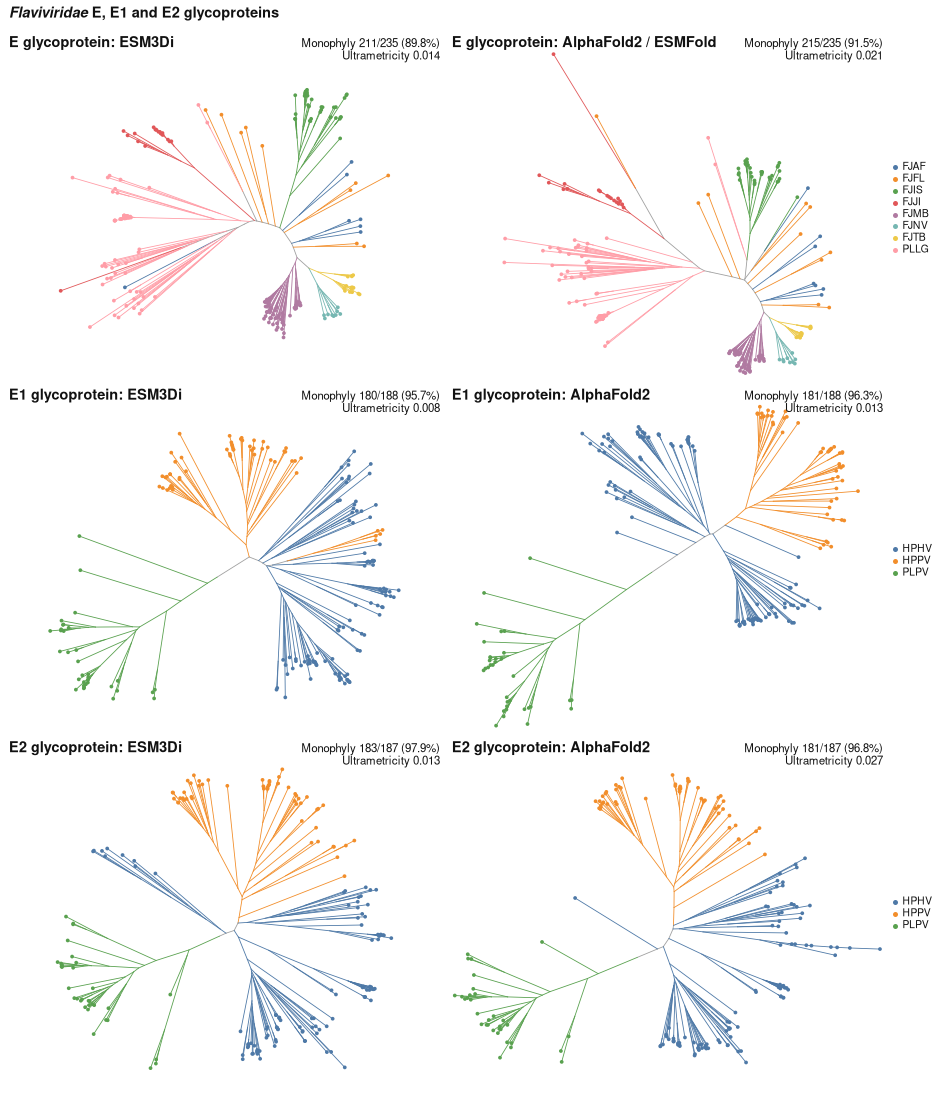

In [7]:
METHOD_TITLES = {"esm3di": "ESM3Di", "af2": "AlphaFold2"}


def classified_tree(model, protein):
    return classified_trees[model, f"fullglyco_{protein}"]


def tree_entry(model, protein, title, part=None):
    """A tree with its monophyletic internal nodes (``183/187 (97.9%)``) and ultrametricity (lower: more ultrametric)."""
    tree = classified_tree(model, protein)
    monophyletic, internal, fraction = score_monophyly(tree, verbose=False)
    return dict(file=tree, title=title, part=part,
                corner=[f"Monophyly {monophyletic}/{internal} ({fraction:.1%})",
                        f"Ultrametricity {ultrametricity(tree):.3f}"])


proteins = ("E", "E1", "E2")
colors = group_colors(tip_keys([classified_tree("esm3di", p) for p in proteins], MODE))
style = dict(mode=MODE, colors=colors)

# Figure 2b
# Its scores go in one table above the trees, as in panel a.
panel_b = [dict(file=classified_tree(m, "E2"), title=METHOD_TITLES[m], part=m) for m in TREES]
e2_scores = dict(columns=("Monophyly", "Ultrametricity"),
                 rows=[(tree["title"], f"{score_monophyly(tree['file'], verbose=False)[2]:.1%}", f"{ultrametricity(tree['file']):.3f}")
                       for tree in panel_b])
tree_grid([[tree] for tree in panel_b],
          FIGURE_DIR / "flaviviridae_e2_trees",
          legend_blocks=group_legend(colors, tip_keys([tree["file"] for tree in panel_b], MODE)),
          legend_inside=True, legend_middle=True, score_table=e2_scores, score_table_top_mm=FIGURE2_SCORE_TABLE_TOP_MM, tree_width_mm=55, height_mm=FIGURE2_PANEL_HEIGHT_MM, parts_dir=FIGURE_DIR / "parts", **style)


# Supplementary figure: one row per protein, each at its own scale
def method_title(protein, model):
    if protein == "E" and model == "af2":
        return "E glycoprotein: AlphaFold2 / ESMFold"   # 51 of the E structures come from ESMFold
    return f"{protein} glycoprotein: {METHOD_TITLES[model]}"


tree_grid([[tree_entry(m, p, method_title(p, m)) for m in TREES] for p in proteins],
          FIGURE_DIR / "flaviviridae_glycoprotein_trees",
          legend_blocks=[group_legend(colors, tip_keys([classified_tree("esm3di", p)], MODE)) for p in proteins],
          legend_per_row=True, tree_width_mm=75, tree_height_mm=55, scale_by="row",
          heading=[("Flaviviridae", dict(fontweight="bold", fontstyle="italic")),
                   (" E, E1 and E2 glycoproteins", dict(fontweight="bold"))], **style)